# SOMSense (ESRC Soil Organic Matter Intelligence) — Reproducible Research Pipeline

This notebook reproduces the end-to-end scientific workflow for calibrated estimation of Soil Organic Carbon (`%SOC`), Soil Organic Matter (`%SOM = k * max(0, SOC_hat)`, default `k = 1.724`), and Permanganate-Oxidizable Carbon (`POXC` in `mg C/kg dry soil`) across three verified public datasets and the `ESRC Device - 1` hardware telemetry schema.

**Scientific Guardrails Enforced:**
1. **No direct sensor `%OM` reporting:** Every output provides point estimate, 95% conformal prediction interval, model version, and calibration domain status (`In-Range`, `Caution`, `Outside Calibration Range`).
2. **Circular leakage exclusion (`SRDI Kushtia`):** `TN_pct` was arithmetically derived from `OM_pct` (`TN = 0.0492 * OM - 0.0065, r = 0.978`) and is strictly excluded from training predictors.
3. **Mineral-only limitation (`Kaggle Soil Fertility`):** After flagging 7 physically corrupt rows (`pH < 3.0` / `> 10.0`, `OC = 24.0%`, `Zn = 42.0 / Fe = 44.0`), 5 mineral features (`N, P, K, pH, EC`) yield near-zero/negative cross-validated `R^2` without Temperature, Moisture, and local AEZ calibration.
4. **Unit normalization (`USDA KSSL POX-C`):** `Table.S1` `SOC` values are in `g C/kg` (divided by `10.0` to obtain `%SOC`, verified against `Ratio_poxc-soc`). `Passive C != Total SOC - POXC` is enforced.
5. **Hardware & physics gates (`ESRC Device - 1`):** `pH = 0.12` (`< 3.0` or `> 10.0`) emits `SENSOR_FAULT_CRITICAL` and blocks silent inference; `Humidity = 100%` (`>= 98%`) emits `SATURATION_DISTURBANCE_WARNING`.

In [1]:
from __future__ import annotations

import json
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message=".*IProgress.*")

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

print("Repository:", ROOT_DIR.name)

Repository: FYDP


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml_core.conformal_uncertainty import evaluate_oof_conformal
from ml_core.datasets import (
    load_kaggle_soil_fertility,
    load_srdi_kushtia,
    load_usda_kssl_poxc,
)
from ml_core.esrc_adapter import parse_esrc_json
from ml_core.export_artifacts import (
    canonical_sha256,
    predict_from_registry_entry,
    verify_registry_parity,
)
from ml_core.ood_detector import OODDetector
from ml_core.poxc_pipeline import enforce_no_passive_c_subtraction, train_poxc_pipeline
from ml_core.spatial_cv import compute_srdi_leakage_comparison, evaluate_model_ladder

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})

## 1. Datasets, Unit Harmonization, and Real Data Audits

In [3]:
srdi = load_srdi_kushtia(include_leaked_tn=False)
kaggle = load_kaggle_soil_fertility(allow_fixture_fallback=False)
usda_with_soc = load_usda_kssl_poxc(include_lab_soc=True)
usda_no_soc = load_usda_kssl_poxc(include_lab_soc=False)

srdi_corr = srdi.audit_info["tn_om_correlation"]
usda_valid = usda_with_soc.audit_info["valid_quantified_rows"]
usda_total = usda_with_soc.audit_info["standard_rows_total"]

summary_df = pd.DataFrame(
    [
        {
            "Dataset": "SRDI Kushtia (Mendeley)",
            "Rows (Clean / Total)": f"{len(srdi.df)} / {srdi.audit_info['n_rows']}",
            "Groups": f"{srdi.audit_info['n_unique_sites']} Sample_IDs",
            "Target": f"{srdi.target_column} ({srdi.target_unit})",
            "Audit Finding": f"K_cmol*391; TN excluded (r={srdi_corr:.4f})",
        },
        {
            "Dataset": "Kaggle Soil Fertility",
            "Rows (Clean / Total)": (
                f"{kaggle.audit_info['clean_rows']} / {kaggle.audit_info['raw_rows']}"
            ),
            "Groups": "None (5-fold KFold)",
            "Target": f"{kaggle.target_column} ({kaggle.target_unit})",
            "Audit Finding": f"{kaggle.audit_info['flagged_outlier_rows']} corrupt rows flagged",
        },
        {
            "Dataset": "USDA KSSL POX-C (<2 mm, 2.5 g)",
            "Rows (Clean / Total)": f"{usda_valid} / {usda_total}",
            "Groups": f"{usda_with_soc.audit_info['valid_pedons']} Pedon_IDs",
            "Target": f"{usda_with_soc.target_column} ({usda_with_soc.target_unit})",
            "Audit Finding": "SOC/10 g/kg->%; 4 NaN reagent-exhausted rows",
        },
    ]
)
display(summary_df)
print("\nFlagged Kaggle corrupt rows:")
display(kaggle.excluded_df[["N", "P", "K", "pH", "EC", "OC", "Zn", "Fe", "outlier_reason"]])

,Dataset,Rows (Clean / Total),Groups,Target,Audit Finding
0,SRDI Kushtia (Mendeley),171 / 171,57 Sample_IDs,om_pct (%),K_cmol*391; TN excluded (r=0.9776)
1,Kaggle Soil Fertility,873 / 880,None (5-fold KFold),oc_pct (%),7 corrupt rows flagged
2,"USDA KSSL POX-C (<2 mm, 2.5 g)",38 / 42,35 Pedon_IDs,poxc_mg_kg (mg C/kg dry soil),SOC/10 g/kg->%; 4 NaN reagent-exhausted rows



Flagged Kaggle corrupt rows:


,N,P,K,pH,EC,OC,Zn,Fe,outlier_reason
0,301,9.9,359,0.90,0.52,0.88,0.43,6.33,"pH=0.90 outside [3.0, 10.0]"
1,314,8.6,391,0.90,0.56,0.98,0.51,1.78,"pH=0.90 outside [3.0, 10.0]"
2,295,13.4,412,10.05,0.73,0.68,0.52,3.31,"pH=10.05 outside [3.0, 10.0]"
3,326,11.8,444,10.60,0.88,0.88,0.43,6.52,"pH=10.60 outside [3.0, 10.0]"
4,358,12.5,581,11.15,0.51,0.49,0.28,4.13,"pH=11.15 outside [3.0, 10.0]"
5,320,3.9,507,7.40,0.34,0.51,42.00,44.00,Zn=42.00 > 10.0; Fe=44.00 > 20.0
6,364,6.8,444,7.50,0.55,24.00,38.00,34.00,"OC=24.00% outside [0, 5.0]; Zn=38.00 > 10.0; F..."


## 2. SRDI Circular Leakage Audit (`TN_pct` vs Non-Leaked Predictors)

,Setup,Random KFold R2,GroupKFold(Sample_ID) R2,GroupKFold RMSE
0,With Leaked TN_pct,0.953163,0.952133,0.079577
1,"Clean (TN_pct Excluded, OLS)",0.006621,0.074228,0.349960


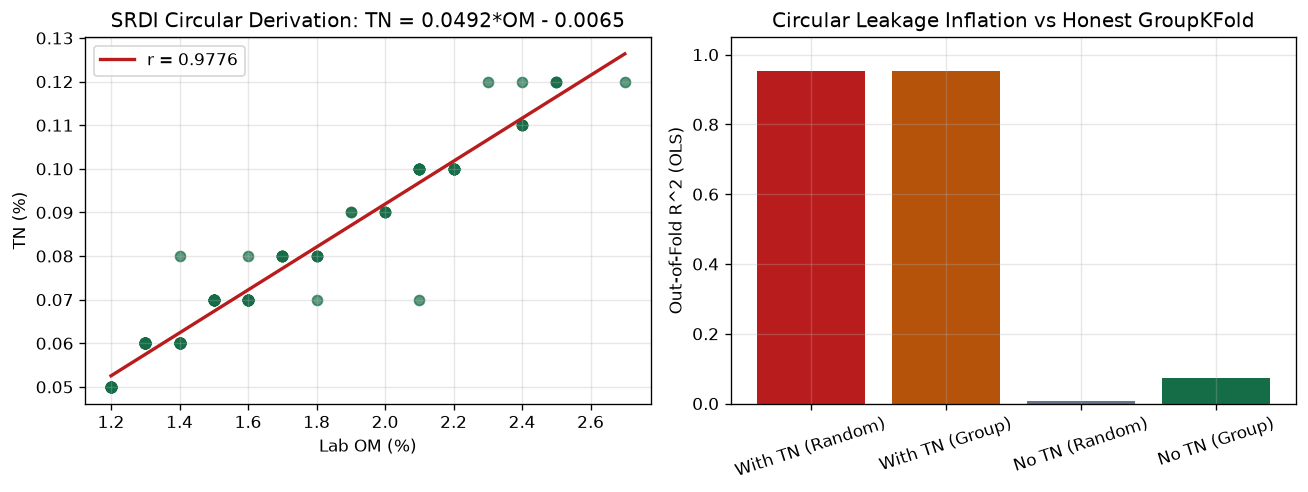

In [4]:
leak_audit = compute_srdi_leakage_comparison(random_state=42)
leak_table = pd.DataFrame(
    [
        {
            "Setup": "With Leaked TN_pct",
            "Random KFold R2": leak_audit["with_tn_random_r2"],
            "GroupKFold(Sample_ID) R2": leak_audit["with_tn_group_r2"],
            "GroupKFold RMSE": leak_audit["with_tn_group_rmse"],
        },
        {
            "Setup": "Clean (TN_pct Excluded, OLS)",
            "Random KFold R2": leak_audit["without_tn_random_r2"],
            "GroupKFold(Sample_ID) R2": leak_audit["without_tn_group_r2"],
            "GroupKFold RMSE": leak_audit["without_tn_group_rmse"],
        },
    ]
)
display(leak_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(srdi.df["om_pct"], srdi.df["total_nitrogen_pct"], alpha=0.7, color="#156D47")
om_grid = np.linspace(srdi.df["om_pct"].min(), srdi.df["om_pct"].max(), 50)
axes[0].plot(
    om_grid,
    srdi.audit_info["tn_om_slope"] * om_grid + srdi.audit_info["tn_om_intercept"],
    color="#B91C1C",
    lw=2,
    label=f"r = {leak_audit['tn_om_correlation']:.4f}",
)
axes[0].set_xlabel("Lab OM (%)")
axes[0].set_ylabel("TN (%)")
axes[0].set_title("SRDI Circular Derivation: TN = 0.0492*OM - 0.0065")
axes[0].legend()

bars = ["With TN (Random)", "With TN (Group)", "No TN (Random)", "No TN (Group)"]
vals = [
    leak_audit["with_tn_random_r2"],
    leak_audit["with_tn_group_r2"],
    leak_audit["without_tn_random_r2"],
    leak_audit["without_tn_group_r2"],
]
colors = ["#B91C1C", "#B45309", "#64748B", "#156D47"]
axes[1].bar(bars, vals, color=colors)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Out-of-Fold R^2 (OLS)")
axes[1].set_title("Circular Leakage Inflation vs Honest GroupKFold")
axes[1].tick_params(axis="x", rotation=18)
plt.tight_layout()
plt.show()

## 3. Model Benchmark Ladders, Conformal 95% Coverage, and OOD Detection

In [5]:
srdi_eval = evaluate_model_ladder(srdi, n_splits=5, random_state=42)
kaggle_eval = evaluate_model_ladder(kaggle, n_splits=5, random_state=42)
poxc_with = train_poxc_pipeline(include_lab_soc=True, n_splits=5, random_state=42)
poxc_without = train_poxc_pipeline(include_lab_soc=False, n_splits=5, random_state=42)


def ladder_df(ev, title: str) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "Benchmark": title,
                "Model": r.spec.key,
                "RMSE": round(r.rmse, 4),
                "MAE": round(r.mae, 4),
                "R2": round(r.r2, 4),
                "Beats OLS": r.beats_ols_baseline,
                "Retained": r.retained,
            }
            for r in ev.all_results
        ]
    )


all_ladders = pd.concat(
    [
        ladder_df(srdi_eval, "SRDI Kushtia (OM%)"),
        ladder_df(kaggle_eval, "Kaggle Clean (OC%)"),
        ladder_df(poxc_with.evaluation, "USDA POXC (With Lab SOC)"),
        ladder_df(poxc_without.evaluation, "USDA POXC (No Lab SOC)"),
    ],
    ignore_index=True,
)
display(all_ladders)

,Benchmark,Model,RMSE,MAE,R2,Beats OLS,Retained
0,SRDI Kushtia (OM%),ols_interaction,0.3500,0.2847,0.0742,False,True
1,SRDI Kushtia (OM%),ridge,0.3493,0.2846,0.0776,True,True
2,SRDI Kushtia (OM%),elastic_net,0.3521,0.2865,0.0630,False,False
3,SRDI Kushtia (OM%),huber,0.3617,0.2694,0.0112,False,False
4,SRDI Kushtia (OM%),random_forest,0.3396,0.2641,0.1283,True,True
5,SRDI Kushtia (OM%),hist_gradient_boosting,0.3307,0.2588,0.1734,True,True
6,SRDI Kushtia (OM%),lightgbm,0.3318,0.2622,0.1676,True,True
7,Kaggle Clean (OC%),ols_interaction,0.2976,0.2496,-0.0044,False,True
8,Kaggle Clean (OC%),ridge,0.2975,0.2495,-0.0042,True,True
9,Kaggle Clean (OC%),elastic_net,0.2970,0.2489,-0.0007,True,True


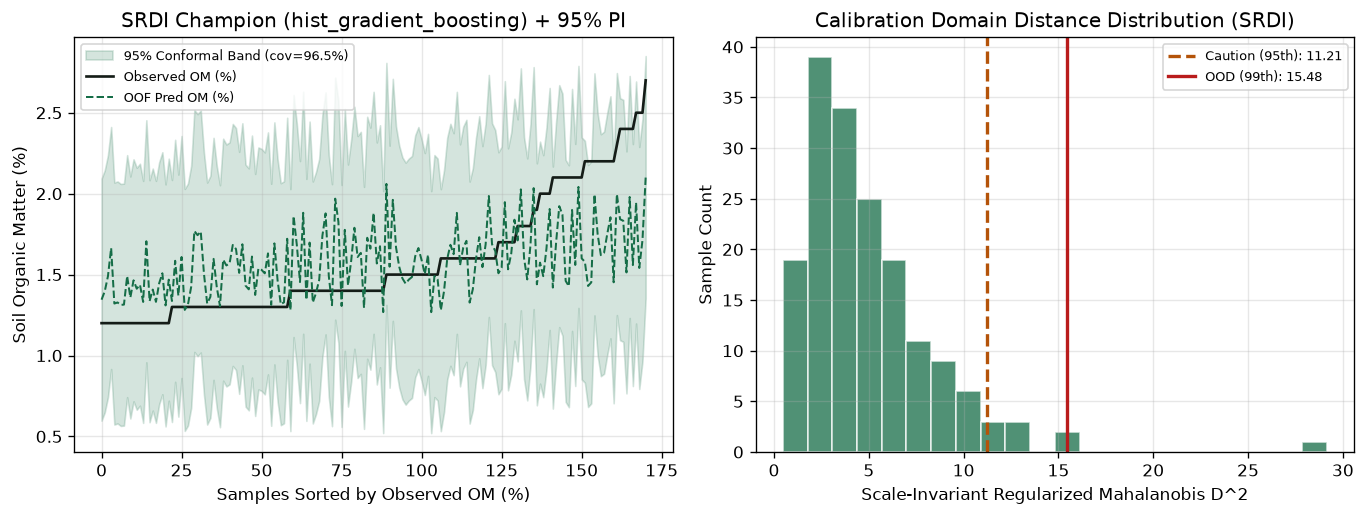

In [6]:
# Conformal 95% intervals + OOD Mahalanobis D^2 visualizations on SRDI Champion
srdi_y = srdi.df[srdi.target_column].to_numpy(dtype=np.float64)
srdi_oof = srdi_eval.champion_result.oof_predictions
srdi_conf = evaluate_oof_conformal(
    srdi_y, srdi_oof, srdi_eval.champion_result.fold_ids, alpha=0.05
)
srdi_X = srdi.df[srdi.feature_columns].to_numpy(dtype=np.float64)
srdi_ood = OODDetector(srdi.feature_columns, random_state=42).fit(srdi_X)
d2_scores = [srdi_ood.mahalanobis_d2(row) for row in srdi_X]

lo = np.maximum(0.0, srdi_oof - srdi_conf.q_quantile)
hi = srdi_oof + srdi_conf.q_quantile

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
order = np.argsort(srdi_y)
axes[0].fill_between(
    np.arange(len(srdi_y)),
    lo[order],
    hi[order],
    color="#156D47",
    alpha=0.18,
    label=f"95% Conformal Band (cov={srdi_conf.empirical_coverage:.1%})",
)
axes[0].plot(
    np.arange(len(srdi_y)), srdi_y[order], color="#141C17", lw=1.6, label="Observed OM (%)"
)
axes[0].plot(
    np.arange(len(srdi_y)),
    srdi_oof[order],
    color="#156D47",
    lw=1.2,
    ls="--",
    label="OOF Pred OM (%)",
)
axes[0].set_xlabel("Samples Sorted by Observed OM (%)")
axes[0].set_ylabel("Soil Organic Matter (%)")
axes[0].set_title(f"SRDI Champion ({srdi_eval.champion_result.spec.key}) + 95% PI")
axes[0].legend(fontsize=8)

caution_lbl = f"Caution (95th): {srdi_ood.d2_caution_threshold_:.2f}"
ood_lbl = f"OOD (99th): {srdi_ood.d2_ood_threshold_:.2f}"
axes[1].hist(d2_scores, bins=22, color="#156D47", alpha=0.75, edgecolor="white")
axes[1].axvline(srdi_ood.d2_caution_threshold_, color="#B45309", lw=2, ls="--", label=caution_lbl)
axes[1].axvline(srdi_ood.d2_ood_threshold_, color="#B91C1C", lw=2, ls="-", label=ood_lbl)
axes[1].set_xlabel("Scale-Invariant Regularized Mahalanobis D^2")
axes[1].set_ylabel("Sample Count")
axes[1].set_title("Calibration Domain Distance Distribution (SRDI)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. ESRC Device - 1 Diagnostics, Passive C Guardrail, & Registry `<1e-6` Parity

In [7]:
# Real cumilla 2 / ESRC Device - 1 fault & saturation check
cumilla_payload = json.dumps(
    {
        "device": "ESRC Device - 1",
        "location": "cumilla 2",
        "created_at": "2026-09-29T10:15:00+06:00",
        "Temperature": 29.4,
        "Humidity": 100.0,
        "EC": 620.0,
        "ec_unit": "uS/cm",
        "Salinity": 395.0,
        "PH": 0.12,
        "Nitrogen": 185.0,
        "Phosphorus": 19.2,
        "Potassium": 178.0,
    }
)
_, cumilla_report = parse_esrc_json(cumilla_payload)[0]
print("cumilla 2 passed_hard_gates:", cumilla_report.passed_hard_gates)
for fl in cumilla_report.flags:
    print(f" - [{fl.severity}] {fl.code}: {fl.message}")

# Passive C guardrail verification
try:
    enforce_no_passive_c_subtraction(total_soc_pct=2.8, poxc_mg_kg=813.0)
except ValueError as exc:
    print("\nPassive C guardrail caught invalid subtraction:", exc)

# Verify exported models/registry.json hashes and <1e-6 parity
registry = json.loads((ROOT_DIR / "models" / "registry.json").read_text(encoding="utf-8"))
payload_no_int = {k: v for k, v in registry.items() if k != "integrity"}
assert canonical_sha256(payload_no_int) == registry["integrity"]["canonical_payload_sha256"]

sample_srdi = {col: float(srdi.df.iloc[0][col]) for col in srdi.feature_columns}
pred_pt, pred_lo, pred_hi, domain_status, _ = predict_from_registry_entry(
    registry["models"]["srdi_kushtia_om_champion"], sample_srdi
)
print(
    f"\nSample_ID 1 JSON inference: {pred_pt:.4f}% SOM "
    f"[95% PI: {pred_lo:.4f}%, {pred_hi:.4f}%] ({domain_status})"
)

parity_rows = [
    ("srdi_kushtia_om_champion", srdi_eval.champion_pipeline, srdi),
    ("srdi_kushtia_om_baseline_ols", srdi_eval.baseline_pipeline, srdi),
    ("kaggle_mineral_oc_benchmark", kaggle_eval.baseline_pipeline, kaggle),
    ("usda_kssl_poxc_with_soc", poxc_with.evaluation.champion_pipeline, usda_with_soc),
    ("usda_kssl_poxc_without_soc", poxc_without.evaluation.champion_pipeline, usda_no_soc),
]
parity_summary = []
for mid, pipe, bnd in parity_rows:
    diff = verify_registry_parity(registry["models"][mid], pipe, bnd, tolerance=1e-6)
    parity_summary.append(
        {"model_id": mid, "max_abs_diff": diff, "parity_under_1e_6": diff < 1e-6}
    )
display(pd.DataFrame(parity_summary))

cumilla 2 passed_hard_gates: False
 - [CRITICAL] SENSOR_FAULT_CRITICAL: Critical pH sensor fault on ESRC Device - 1 (cumilla 2): pH=0.12 is outside physical arable soil bounds [3.0, 10.0].
 - [WARNING] SATURATION_DISTURBANCE_WARNING: Soil moisture/humidity is 100.0% (>= 98%) on ESRC Device - 1 (cumilla 2); standing water or post-rain saturation inflates apparent bulk EC via EC*Moisture cross-talk.

Passive C guardrail caught invalid subtraction: PASSIVE_CARBON_GUARDRAIL_VIOLATION: Passive carbon cannot be computed as Total SOC - POXC without full physical fractionation (MAOC/POM) data.

Sample_ID 1 JSON inference: 2.1767% SOM [95% PI: 1.4291%, 2.9243%] (In-Range)


,model_id,max_abs_diff,parity_under_1e_6
0,srdi_kushtia_om_champion,1.554312e-15,True
1,srdi_kushtia_om_baseline_ols,2.220446e-16,True
2,kaggle_mineral_oc_benchmark,1.110223e-16,True
3,usda_kssl_poxc_with_soc,2.273737e-13,True
4,usda_kssl_poxc_without_soc,4.547474e-13,True
